# Paper 1: KG-guided concept-based skin disease diagnosis (no images)

**Task.** Given the dermatologist-annotated morphological concepts of a lesion $x\in\{0,1\}^{48}$, predict the disease ($K=113$). Coarse labels (9 categories, 3 super-categories) are used for hierarchical analysis.

**Inputs from `dermkg_build.ipynb`**: `split.csv`, `clinical_rules.csv`, `triples_infer.csv` (val/test labels already removed).

**Model families**
1. Data-only baselines: logistic regression, Bernoulli NB, kNN (Jaccard), random forest, gradient boosting, MLP
2. Non-parametric KG models: concept-profile likelihood with global shrinkage (KG-Profile), hierarchical shrinkage along `IS_A` / `SUBCLASS_OF` (KG-Hier), rule chain score (KG-Rule)
3. KG-Fusion: log-linear fusion of the best baseline, KG-Hier and rule chain scores, weights tuned on val
4. DermKG-Net: a GNN (GCN / GAT) over the disease-level KG producing disease prototypes; images are encoded from KG-contextualized concept embeddings

**Protocol.** Hyperparameters are selected on val (macro-F1); test is touched once. Metrics: top-1, top-5, macro-F1, balanced accuracy, many / medium / few-shot accuracy, category-level consistency, bootstrap 95% CI.

In [ ]:
# %pip install pandas numpy scikit-learn matplotlib torch -i https://pypi.tuna.tsinghua.edu.cn/simple

## 1. Config

In [1]:
SKINCON_CSV = "image.csv"
F17K_CSV = "fitzpatrick17k.csv"
KG_DIR = "data/dermkg"            # output of dermkg_build.ipynb
OUT_DIR = "results/paper1"
SEED = 42
GNN_SEEDS = [0, 1, 2]
N_BOOT = 1000

In [2]:
import os, ast, json, itertools, time, warnings
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import BernoulliNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import f1_score, balanced_accuracy_score, top_k_accuracy_score, confusion_matrix

warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
os.makedirs(OUT_DIR, exist_ok=True)
FIG_DIR = os.path.join(OUT_DIR, "figures"); os.makedirs(FIG_DIR, exist_ok=True)

## 2. Load data and KG artifacts

In [3]:
sk = pd.read_csv(SKINCON_CSV).drop(columns=["Unnamed: 0"], errors="ignore")
sk = sk[sk["Do not consider this image"] == 0].drop(columns=["Do not consider this image"])
sk["md5"] = sk["ImageID"].str.replace(".jpg", "", regex=False)
CONCEPTS = [c for c in sk.columns if c not in ("ImageID", "md5")]
f17k = pd.read_csv(F17K_CSV)
df = sk.merge(f17k, left_on="md5", right_on="md5hash", how="inner")
df = df.merge(pd.read_csv(os.path.join(KG_DIR, "split.csv"))[["md5", "split"]], on="md5").reset_index(drop=True)
df["skin_type"] = df["fitzpatrick_scale"].map(lambda v: f"FST-{int(v)}" if v in range(1, 7) else "FST-unknown")

DISEASES = sorted(df["label"].unique()); K = len(DISEASES)
D_IDX = {d: i for i, d in enumerate(DISEASES)}
D2CAT = df.groupby("label")["nine_partition_label"].first().to_dict()
CAT2SUP = df.groupby("nine_partition_label")["three_partition_label"].first().to_dict()
CATS = sorted(set(D2CAT.values())); SUPS = sorted(set(CAT2SUP.values()))
d2c = np.array([CATS.index(D2CAT[d]) for d in DISEASES])
d2s = np.array([SUPS.index(CAT2SUP[D2CAT[d]]) for d in DISEASES])

X = df[CONCEPTS].values.astype(np.float32)
y = df["label"].map(D_IDX).values
tr, va, te = (df["split"].values == s for s in ("train", "val", "test"))
Xtr, Xva, Xte, ytr, yva, yte = X[tr], X[va], X[te], y[tr], y[va], y[te]
print(f"train {tr.sum()} | val {va.sum()} | test {te.sum()} | K={K} | D={len(CONCEPTS)}")

rules = pd.read_csv(os.path.join(KG_DIR, "clinical_rules.csv"))
rules["premise"] = rules["premise"].map(json.loads)
rules["targets"] = rules["targets"].map(ast.literal_eval)
triples = pd.read_csv(os.path.join(KG_DIR, "triples_infer.csv"))
print(f"rules: {len(rules)} ({(rules.origin=='expert').sum()} expert) | triples: {len(triples)}")
assert not ((triples.relation == "DIAGNOSED_AS") & triples.split.isin(["val", "test"])).any(), "leakage!"

train 2259 | val 324 | test 647 | K=113 | D=48
rules: 37 (20 expert) | triples: 18394


### 2.1 Shot groups

Classes are grouped by their number of **training** images.

In [4]:
n_train = np.bincount(ytr, minlength=K)
MANY, FEW = 20, 8                      # many: >= 20, medium: 8-19, few: < 8 training images
shot = np.where(n_train >= MANY, "many", np.where(n_train >= FEW, "medium", "few"))
print(pd.Series(shot).value_counts().reindex(["many", "medium", "few"]).to_string())
print("train images per class: min", n_train.min(), "median", int(np.median(n_train)), "max", n_train.max())

many      34
medium    63
few       16
train images per class: min 1 median 15 max 88


### 2.2 Information ceiling of the concept input

Many lesions share exactly the same concept vector (for example, Plaque + Erythema alone). For any classifier that only sees $x$, accuracy is bounded by predicting the majority label of each distinct vector. The in-sample oracle below (fit and scored on all data) is an optimistic upper bound and frames what concept-only diagnosis can achieve at each level of the hierarchy.

In [5]:
key = pd.Series(["".join(map(str, r)) for r in X.astype(int)])
print(f"distinct concept vectors: {key.nunique()} / {len(key)}")
CEIL = {}
for lvl, lab in (("disease", df["label"]), ("category", df["nine_partition_label"]), ("super", df["three_partition_label"])):
    CEIL[lvl] = lab.groupby(key.values).agg(lambda s: s.value_counts().iloc[0]).sum() / len(lab)
    print(f"  {lvl:9s} top-1 ceiling: {CEIL[lvl]:.3f}")
vc = key.value_counts()
print("most frequent vectors:")
for k, n in vc.head(5).items():
    print(f"  {n:4d} ({n/len(key):.1%})", [CONCEPTS[i] for i, ch in enumerate(k) if ch == "1"])

distinct concept vectors: 813 / 3230
  disease   top-1 ceiling: 0.389
  category  top-1 ceiling: 0.776
  super     top-1 ceiling: 0.822
most frequent vectors:
   358 (11.1%) ['Plaque', 'Erythema']
   217 (6.7%) ['Plaque', 'Scale', 'Erythema']
   202 (6.3%) ['Papule', 'Erythema']
   138 (4.3%) ['Plaque', 'Brown(Hyperpigmentation)']
    86 (2.7%) ['Papule', 'Plaque', 'Erythema']


## 3. Evaluation utilities

In [6]:
def evaluate(P, yt, name=None):
    """P: (n, K) scores or probabilities, yt: true indices."""
    pred = P.argmax(1)
    acc_c = (np.bincount(yt, weights=(pred == yt), minlength=K) / np.maximum(np.bincount(yt, minlength=K), 1))
    present = np.bincount(yt, minlength=K) > 0
    out = {
        "top1": (pred == yt).mean(),
        "top5": top_k_accuracy_score(yt, P, k=5, labels=np.arange(K)),
        "macroF1": f1_score(yt, pred, average="macro", labels=np.unique(yt), zero_division=0),
        "balAcc": balanced_accuracy_score(yt, pred),
        "cat_acc": (d2c[pred] == d2c[yt]).mean(),       # category-level consistency
        "sup_acc": (d2s[pred] == d2s[yt]).mean(),
    }
    for g in ("many", "medium", "few"):
        m = present & (shot == g)
        out[f"{g}"] = acc_c[m].mean() if m.any() else np.nan
    if name:
        out = {"model": name, **out}
    return out


def boot_ci(P, yt, metric="macroF1", n=N_BOOT, seed=SEED):
    r = np.random.default_rng(seed); pred = P.argmax(1); vals = []
    for _ in range(n):
        i = r.integers(0, len(yt), len(yt))
        if metric == "macroF1":
            vals.append(f1_score(yt[i], pred[i], average="macro", labels=np.unique(yt[i]), zero_division=0))
        else:
            vals.append((pred[i] == yt[i]).mean())
    return np.percentile(vals, [2.5, 97.5])


def softmax(Z, axis=1):
    Z = Z - Z.max(axis, keepdims=True); E = np.exp(Z); return E / E.sum(axis, keepdims=True)


VAL, TEST, PROBS = {}, {}, {}      # val metrics, test metrics, test probabilities per model

## 4. Data-only baselines

Each baseline gets a small grid on val (macro-F1).

In [7]:
BASELINES = {
    "LogReg": (lambda p: LogisticRegression(C=p, max_iter=3000), [0.1, 1.0, 10.0]),
    "BernoulliNB": (lambda p: BernoulliNB(alpha=p), [0.1, 0.5, 1.0]),
    "kNN-Jaccard": (lambda p: KNeighborsClassifier(n_neighbors=p, metric="jaccard", weights="distance"), [5, 10, 20]),
    "RandomForest": (lambda p: RandomForestClassifier(n_estimators=500, min_samples_leaf=p, n_jobs=-1,
                                                      random_state=SEED), [1, 2, 4]),
    "GradBoost": (lambda p: HistGradientBoostingClassifier(learning_rate=p, max_iter=150, early_stopping=False,
                                                           random_state=SEED), [0.05, 0.1]),
    "MLP": (lambda p: MLPClassifier(hidden_layer_sizes=(256,), alpha=p, max_iter=600, early_stopping=True,
                                    random_state=SEED), [1e-4, 1e-3, 1e-2]),
}
Xb = lambda A: A.astype(bool)
for name, (make, grid) in BASELINES.items():
    t0 = time.time(); best = (-1, None, None)
    for p in grid:
        m = make(p)
        Xin = (Xb(Xtr), Xb(Xva)) if name == "kNN-Jaccard" else (Xtr, Xva)
        m.fit(Xin[0], ytr)
        f = f1_score(yva, m.predict(Xin[1]), average="macro", zero_division=0)
        if f > best[0]:
            best = (f, p, m)
    f, p, m = best
    Xt, Xv = (Xb(Xte), Xb(Xva)) if name == "kNN-Jaccard" else (Xte, Xva)
    assert list(m.classes_) == list(range(K))
    VAL[name] = evaluate(m.predict_proba(Xv), yva, name)
    PROBS[name] = m.predict_proba(Xt)
    TEST[name] = evaluate(PROBS[name], yte, name)
    print(f"{name:13s} best={p!s:7s} val F1={f:.3f} test F1={TEST[name]['macroF1']:.3f} ({time.time()-t0:.0f}s)")

LogReg        best=10.0    val F1=0.133 test F1=0.110 (1s)
BernoulliNB   best=0.1     val F1=0.137 test F1=0.114 (0s)
kNN-Jaccard   best=10      val F1=0.116 test F1=0.111 (0s)
RandomForest  best=1       val F1=0.123 test F1=0.096 (3s)
GradBoost     best=0.1     val F1=0.112 test F1=0.099 (58s)
MLP           best=0.01    val F1=0.100 test F1=0.105 (2s)


## 5. Non-parametric KG models

**KG-Profile.** Bernoulli likelihood over the disease concept profile, shrunk toward the global prior:
$$p_d(c)=\frac{n_{dc}+\alpha\,p(c)}{n_d+\alpha}$$

**KG-Hier.** Shrinkage follows the KG hierarchy `Disease -IS_A-> Category -SUBCLASS_OF-> Super`, so a tail disease borrows strength from its parent category instead of the whole dataset:
$$p_s(c)=\frac{n_{sc}+\alpha_0 p(c)}{n_s+\alpha_0},\quad p_k(c)=\frac{n_{kc}+\alpha_1 p_{s(k)}(c)}{n_k+\alpha_1},\quad p_d(c)=\frac{n_{dc}+\alpha_2 p_{k(d)}(c)}{n_d+\alpha_2}$$

Both score $\log P(d\mid x)\propto \tau\log\pi_d+\sum_c x_c\log p_d(c)+(1-x_c)\log(1-p_d(c))$, where $\tau$ tempers the class prior ($\tau=0$ is uniform, favoring tail classes).

**KG-Rule.** Chain score $\mathrm{CS}(i,d)=\sum_{r\in\mathcal R(i)} w_r\mathbb 1[d\in T_r]$ from the activated clinical rules.

In [8]:
def profiles(alpha2, alpha1=5.0, alpha0=5.0, hier=True):
    p_c = Xtr.mean(0)
    Y = np.eye(K)[ytr]                                    # n x K
    n_d, n_dc = Y.sum(0), Y.T @ Xtr                       # K, K x D
    if not hier:
        return (n_dc + alpha2 * p_c) / (n_d[:, None] + alpha2)
    S = np.eye(len(SUPS))[d2s[ytr]]; Kc = np.eye(len(CATS))[d2c[ytr]]
    p_s = (S.T @ Xtr + alpha0 * p_c) / (S.sum(0)[:, None] + alpha0)
    sup_of_cat = np.array([SUPS.index(CAT2SUP[c]) for c in CATS])
    p_k = (Kc.T @ Xtr + alpha1 * p_s[sup_of_cat]) / (Kc.sum(0)[:, None] + alpha1)
    return (n_dc + alpha2 * p_k[d2c]) / (n_d[:, None] + alpha2)


def kg_loglik(Xq, Pd, tau):
    Pd = np.clip(Pd, 1e-4, 1 - 1e-4)
    prior = np.log(np.maximum(n_train, 1) / n_train.sum())
    return tau * prior + Xq @ np.log(Pd).T + (1 - Xq) @ np.log(1 - Pd).T


GRID_A = [0.5, 1, 2, 5, 10, 20]
GRID_TAU = [0.0, 0.5, 1.0]
for name, hier in (("KG-Profile", False), ("KG-Hier", True)):
    best = (-1, None)
    for a, t in itertools.product(GRID_A, GRID_TAU):
        f = f1_score(yva, kg_loglik(Xva, profiles(a, hier=hier), t).argmax(1), average="macro", zero_division=0)
        if f > best[0]:
            best = (f, (a, t))
    a, t = best[1]
    Pd = profiles(a, hier=hier)
    VAL[name] = evaluate(softmax(kg_loglik(Xva, Pd, t)), yva, name)
    PROBS[name] = softmax(kg_loglik(Xte, Pd, t))
    TEST[name] = evaluate(PROBS[name], yte, name)
    print(f"{name:11s} alpha={a} tau={t} | val F1={best[0]:.3f} test F1={TEST[name]['macroF1']:.3f}")
    if name == "KG-Hier":
        PD_HIER, TAU_HIER = Pd, t

KG-Profile  alpha=2 tau=0.5 | val F1=0.167 test F1=0.120
KG-Hier     alpha=2 tau=0.5 | val F1=0.166 test F1=0.118


In [9]:
def premise_mask(Xq, premise):
    m = np.ones(len(Xq), dtype=bool)
    for clause in premise:
        m &= Xq[:, [CONCEPTS.index(c) for c in clause]].sum(1) > 0
    return m

RW = {"strong": 3, "moderate": 2, "weak": 1, "unsupported": 0}
W_R = rules["strength"].map(RW).values.astype(float)
T_R = np.zeros((len(rules), K))
for k, tg in enumerate(rules["targets"]):
    T_R[k, [D_IDX[d] for d in tg]] = 1
ACT = {s: np.stack([premise_mask(A, p) for p in rules["premise"]], 1) for s, A in (("tr", Xtr), ("va", Xva), ("te", Xte))}
CS = {s: (ACT[s] * W_R) @ T_R for s in ACT}
EXPERT = (rules["origin"] == "expert").values
CS_EXP = {s: (ACT[s][:, EXPERT] * W_R[EXPERT]) @ T_R[EXPERT] for s in ACT}

# KG-Rule: chain score, ties broken by the class prior
tie = 1e-3 * np.log(np.maximum(n_train, 1))
VAL["KG-Rule"] = evaluate(CS["va"] + tie, yva, "KG-Rule")
PROBS["KG-Rule"] = softmax(CS["te"] + tie)
TEST["KG-Rule"] = evaluate(CS["te"] + tie, yte, "KG-Rule")
print("KG-Rule test:", {k: round(v, 3) for k, v in TEST["KG-Rule"].items() if k != "model"})
print(f"test images activating >=1 rule: {(ACT['te'].sum(1) > 0).mean():.3f}")

KG-Rule test: {'top1': np.float64(0.114), 'top5': 0.261, 'macroF1': 0.05, 'balAcc': 0.064, 'cat_acc': np.float64(0.351), 'sup_acc': np.float64(0.397), 'many': np.float64(0.135), 'medium': np.float64(0.041), 'few': np.float64(0.0)}
test images activating >=1 rule: 0.447


## 6. KG-Fusion

Log-linear fusion of the best data-only baseline (by val macro-F1), KG-Hier, and the rule chain score:
$$\log P_{\text{fuse}}(d\mid x)=(1-\alpha)\log P_{\text{base}}+\alpha\log P_{\text{KG-Hier}}+\lambda\,\mathrm{CS}(x,d)$$
$\alpha,\lambda$ are tuned on val. $\alpha=0,\lambda=0$ recovers the baseline, so any gain is attributable to the KG.

fusion base: BernoulliNB
best alpha=0.9 lambda=0.1 val F1=0.168
KG-Fusion              alpha=0.9 lambda=0.1 test F1=0.126
KG-Fusion w/o rules    alpha=0.8 lambda=0 test F1=0.116
KG-Fusion w/o KG-Hier  alpha=0 lambda=0.1 test F1=0.117


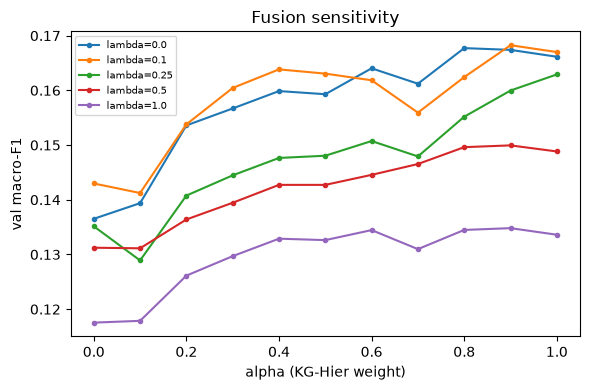

In [10]:
base_name = max([n for n in BASELINES], key=lambda n: VAL[n]["macroF1"])
print("fusion base:", base_name)
mk, grid = BASELINES[base_name]
best_p = None
# refit base with its selected hyperparameter to get val probabilities
for p in grid:
    m = mk(p); Xin = (Xb(Xtr), Xb(Xva)) if base_name == "kNN-Jaccard" else (Xtr, Xva)
    m.fit(Xin[0], ytr)
    f = f1_score(yva, m.predict(Xin[1]), average="macro", zero_division=0)
    if best_p is None or f > best_p[0]:
        best_p = (f, m)
base_m = best_p[1]
Pb_va = base_m.predict_proba(Xb(Xva) if base_name == "kNN-Jaccard" else Xva)
Pb_te = PROBS[base_name]
Lk_va = np.log(softmax(kg_loglik(Xva, PD_HIER, TAU_HIER)) + 1e-9)
Lk_te = np.log(PROBS["KG-Hier"] + 1e-9)

def fuse(Pb, Lk, cs, a, lam):
    return (1 - a) * np.log(Pb + 1e-9) + a * Lk + lam * cs

grid_res = []
for a in np.round(np.arange(0, 1.01, 0.1), 2):
    for lam in [0, 0.1, 0.25, 0.5, 1.0]:
        f = f1_score(yva, fuse(Pb_va, Lk_va, CS["va"], a, lam).argmax(1), average="macro", zero_division=0)
        grid_res.append((a, lam, f))
grid_res = pd.DataFrame(grid_res, columns=["alpha", "lambda", "valF1"])
A_BEST, L_BEST = grid_res.loc[grid_res.valF1.idxmax(), ["alpha", "lambda"]]
print(f"best alpha={A_BEST} lambda={L_BEST} val F1={grid_res.valF1.max():.3f}")

for name, (a, lam) in {"KG-Fusion": (A_BEST, L_BEST),
                       "KG-Fusion w/o rules": (grid_res[grid_res["lambda"] == 0].sort_values("valF1").iloc[-1]["alpha"], 0),
                       "KG-Fusion w/o KG-Hier": (0, grid_res[grid_res.alpha == 0].sort_values("valF1").iloc[-1]["lambda"])}.items():
    VAL[name] = evaluate(softmax(fuse(Pb_va, Lk_va, CS["va"], a, lam)), yva, name)
    PROBS[name] = softmax(fuse(Pb_te, Lk_te, CS["te"], a, lam))
    TEST[name] = evaluate(PROBS[name], yte, name)
    print(f"{name:22s} alpha={a} lambda={lam} test F1={TEST[name]['macroF1']:.3f}")

piv = grid_res.pivot(index="alpha", columns="lambda", values="valF1")
fig, ax = plt.subplots(figsize=(6, 4))
for lam in piv.columns:
    ax.plot(piv.index, piv[lam], marker="o", ms=3, label=f"lambda={lam}")
ax.set_xlabel("alpha (KG-Hier weight)"); ax.set_ylabel("val macro-F1"); ax.legend(fontsize=7); ax.set_title("Fusion sensitivity")
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "fusion_sensitivity.png"), dpi=200); plt.show()

## 7. DermKG-Net (GNN over the disease-level KG)

The KG without image nodes (concepts, concept groups, diseases, categories, super-categories, rules) is encoded by a GNN into node embeddings $H$. An image is represented by its KG-contextualized concept embeddings plus a linear map of $x$:
$$z=\mathrm{LN}\Big(\frac{1}{|x|}\sum_{c:x_c=1}H_c + W_x x\Big),\qquad s(x,d)=\gamma\cos(z, H_d)$$
Diseases are scored against their **KG node embedding** (a prototype), not a free classifier row, so the class representation is defined by the graph. Variants: `noKG` (identity adjacency, i.e. same architecture without edges), `GCN`, `GAT`, `GCN w/o rules`.

Implemented in plain PyTorch with a dense adjacency (the disease-level KG has about 200 nodes), so PyTorch Geometric is not required.

In [11]:
import torch
import torch.nn as nn
import torch.nn.functional as F
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", DEVICE)

KG_RELS = ["BELONGS_TO", "IS_A", "SUBCLASS_OF", "CHARACTERIZED_BY", "CO_OCCURS", "GOVERNED_BY", "INDICATES"]
kg = triples[triples.relation.isin(KG_RELS)].copy()
pmi_max = kg.loc[kg.relation == "CO_OCCURS", "weight"].max()
kg.loc[kg.relation == "CO_OCCURS", "weight"] /= pmi_max                 # PMI to [0, 1]
kg.loc[kg.relation == "INDICATES", "weight"] /= 3.0                      # rule weight 3/2/1 to [0, 1]
kg = kg[kg.weight > 0]
NODES = sorted(set(kg["head"]) | set(kg["tail"]) | {f"Disease:{d}" for d in DISEASES} | {f"Concept:{c}" for c in CONCEPTS})
N_IDX = {n: i for i, n in enumerate(NODES)}
CON_IDX = torch.tensor([N_IDX[f"Concept:{c}"] for c in CONCEPTS])
DIS_IDX = torch.tensor([N_IDX[f"Disease:{d}"] for d in DISEASES])
print(f"KG for GNN: {len(NODES)} nodes, {len(kg)} edges")


def build_adj(drop_rules=False, identity=False):
    A = np.zeros((len(NODES), len(NODES)), dtype=np.float32)
    if not identity:
        e = kg[~kg.relation.isin(["GOVERNED_BY", "INDICATES"])] if drop_rules else kg
        h, t = e["head"].map(N_IDX).values, e["tail"].map(N_IDX).values
        np.maximum.at(A, (h, t), e["weight"].values.astype(np.float32))
        A = np.maximum(A, A.T)                                          # undirected message passing
    A += np.eye(len(NODES), dtype=np.float32)
    return torch.tensor(A)


class DenseGCN(nn.Module):
    def __init__(self, d):
        super().__init__(); self.lin = nn.Linear(d, d)
    def forward(self, H, A):
        dinv = A.sum(1).pow(-0.5)
        return (dinv[:, None] * A * dinv[None, :]) @ self.lin(H)


class DenseGAT(nn.Module):
    def __init__(self, d, heads=4):
        super().__init__(); self.h, self.dh = heads, d // heads
        self.lin = nn.Linear(d, d, bias=False)
        self.a_src = nn.Parameter(torch.randn(heads, self.dh) * 0.1)
        self.a_dst = nn.Parameter(torch.randn(heads, self.dh) * 0.1)
    def forward(self, H, A):
        Z = self.lin(H).view(-1, self.h, self.dh)                        # N x h x dh
        e = (Z * self.a_dst).sum(-1)[:, None, :] + (Z * self.a_src).sum(-1)[None, :, :]   # N x N x h
        e = F.leaky_relu(e, 0.2).masked_fill((A <= 0)[:, :, None], float("-inf"))
        att = torch.softmax(e, dim=1) * A[:, :, None]                    # edge weights modulate attention
        att = att / att.sum(1, keepdim=True).clamp_min(1e-9)
        return torch.einsum("ijh,jhd->ihd", att, Z).reshape(-1, self.h * self.dh)


class DermKGNet(nn.Module):
    def __init__(self, A, kind="gcn", d=128, layers=2, dropout=0.3):
        super().__init__()
        self.register_buffer("A", A)
        self.register_buffer("con_idx", CON_IDX)
        self.register_buffer("dis_idx", DIS_IDX)
        self.emb = nn.Parameter(torch.randn(A.shape[0], d) * 0.1)
        Layer = DenseGCN if kind in ("gcn", "nokg") else DenseGAT
        self.gnn = nn.ModuleList([Layer(d) for _ in range(layers)])
        self.norms = nn.ModuleList([nn.LayerNorm(d) for _ in range(layers)])
        self.wx = nn.Linear(len(CONCEPTS), d)
        self.ln = nn.LayerNorm(d); self.drop = nn.Dropout(dropout)
        self.gamma = nn.Parameter(torch.tensor(10.0))
    def node_emb(self):
        H = self.emb
        for g, n in zip(self.gnn, self.norms):
            H = n(H + self.drop(F.gelu(g(H, self.A))))                   # residual
        return H
    def forward(self, x):
        H = self.node_emb()
        Hc, Hd = H[self.con_idx], H[self.dis_idx]
        z = (x @ Hc) / x.sum(1, keepdim=True).clamp_min(1) + self.wx(x)
        z = self.ln(self.drop(z))
        return self.gamma * F.normalize(z, dim=-1) @ F.normalize(Hd, dim=-1).T


def train_gnn(kind, A, seed, epochs=400, lr=3e-3, wd=1e-4, patience=60, verbose=False):
    torch.manual_seed(seed); np.random.seed(seed)
    model = DermKGNet(A, kind).to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=wd)
    xt, yt_ = torch.tensor(Xtr, device=DEVICE), torch.tensor(ytr, device=DEVICE)
    xv = torch.tensor(Xva, device=DEVICE)
    best, best_state, wait = -1, None, 0
    for ep in range(epochs):
        model.train()
        perm = torch.randperm(len(xt), device=DEVICE)
        for b in perm.split(256):
            loss = F.cross_entropy(model(xt[b]), yt_[b], label_smoothing=0.1)
            opt.zero_grad(); loss.backward(); opt.step()
        if ep % 5 == 0:
            model.eval()
            with torch.no_grad():
                f = f1_score(yva, model(xv).argmax(1).cpu().numpy(), average="macro", zero_division=0)
            if f > best:
                best, wait = f, 0
                best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
            else:
                wait += 5
                if wait >= patience:
                    break
    model.load_state_dict(best_state); model.eval()
    return model, best


@torch.no_grad()
def gnn_probs(model, A_):
    return torch.softmax(model(torch.tensor(A_, device=DEVICE)), 1).cpu().numpy()

device: cpu
KG for GNN: 215 nodes, 827 edges


In [12]:
VARIANTS = {"DermKG-Net (noKG)": ("nokg", build_adj(identity=True)),
            "DermKG-Net (GCN)": ("gcn", build_adj()),
            "DermKG-Net (GCN w/o rules)": ("gcn", build_adj(drop_rules=True)),
            "DermKG-Net (GAT)": ("gat", build_adj())}
GNN_RUNS = {}
for name, (kind, A) in VARIANTS.items():
    t0 = time.time(); runs = []
    for s in GNN_SEEDS:
        m, vf = train_gnn(kind, A.to(DEVICE), s)
        runs.append(dict(seed=s, val=evaluate(gnn_probs(m, Xva), yva), P=gnn_probs(m, Xte), model=m))
    GNN_RUNS[name] = runs
    PROBS[name] = np.mean([r["P"] for r in runs], 0)                    # seed ensemble for downstream analysis
    VAL[name] = {"model": name, **pd.DataFrame([r["val"] for r in runs]).mean().to_dict()}
    per_seed = pd.DataFrame([evaluate(r["P"], yte) for r in runs])
    TEST[name] = {"model": name, **per_seed.mean().to_dict()}
    TEST[name]["macroF1_std"] = per_seed["macroF1"].std()
    print(f"{name:28s} test F1 {per_seed.macroF1.mean():.3f} +/- {per_seed.macroF1.std():.3f} ({time.time()-t0:.0f}s)")

DermKG-Net (noKG)            test F1 0.116 +/- 0.009 (22s)
DermKG-Net (GCN)             test F1 0.107 +/- 0.006 (27s)
DermKG-Net (GCN w/o rules)   test F1 0.107 +/- 0.005 (22s)
DermKG-Net (GAT)             test F1 0.107 +/- 0.006 (39s)


## 8. Main results (test)

GNN rows are mean over seeds (std in `macroF1_std`). 95% CI for macro-F1 by bootstrap over test images.

In [13]:
ORDER = list(BASELINES) + ["KG-Rule", "KG-Profile", "KG-Hier", "KG-Fusion w/o KG-Hier", "KG-Fusion w/o rules",
                            "KG-Fusion"] + list(VARIANTS)
res = pd.DataFrame([TEST[n] for n in ORDER if n in TEST]).set_index("model")
res["F1_CI95"] = [("[%.3f, %.3f]" % tuple(boot_ci(PROBS[n], yte))) for n in res.index]
res["family"] = ["baseline" if n in BASELINES else "GNN" if n.startswith("DermKG") else "KG" for n in res.index]
cols = ["family", "top1", "top5", "macroF1", "F1_CI95", "balAcc", "many", "medium", "few", "cat_acc", "sup_acc"]
display(res[cols].round(3))
print(f"concept-only ceilings (in-sample oracle): disease {CEIL['disease']:.3f} | category {CEIL['category']:.3f} | super {CEIL['super']:.3f}")
res.to_csv(os.path.join(OUT_DIR, "main_results.csv"))
pd.DataFrame([VAL[n] for n in ORDER if n in VAL]).set_index("model").round(4).to_csv(os.path.join(OUT_DIR, "val_results.csv"))

,family,top1,top5,macroF1,F1_CI95,balAcc,many,medium,few,cat_acc,sup_acc
model,,,,,,,,,,,
LogReg,baseline,0.172,0.402,0.110,"[0.087, 0.126]",0.126,0.205,0.114,0.000,0.603,0.683
BernoulliNB,baseline,0.178,0.372,0.114,"[0.093, 0.132]",0.130,0.216,0.114,0.000,0.614,0.692
kNN-Jaccard,baseline,0.170,0.301,0.111,"[0.087, 0.128]",0.123,0.204,0.093,0.067,0.594,0.668
RandomForest,baseline,0.150,0.359,0.096,"[0.074, 0.111]",0.111,0.182,0.099,0.000,0.573,0.648
GradBoost,baseline,0.142,0.355,0.099,"[0.076, 0.118]",0.109,0.178,0.090,0.033,0.563,0.637
MLP,baseline,0.187,0.376,0.105,"[0.087, 0.121]",0.129,0.238,0.100,0.000,0.624,0.689
KG-Rule,KG,0.114,0.261,0.050,"[0.037, 0.059]",0.064,0.135,0.041,0.000,0.351,0.397
KG-Profile,KG,0.165,0.362,0.120,"[0.097, 0.137]",0.145,0.194,0.137,0.067,0.600,0.683
KG-Hier,KG,0.165,0.359,0.118,"[0.096, 0.136]",0.145,0.194,0.145,0.033,0.601,0.680


concept-only ceilings (in-sample oracle): disease 0.389 | category 0.776 | super 0.822


In [14]:
# paired bootstrap: best KG model vs best baseline on test macro-F1
best_base = res.loc[res.family == "baseline", "macroF1"].idxmax()
best_kg = res.loc[res.family != "baseline", "macroF1"].idxmax()
r = np.random.default_rng(SEED); d = []
pa, pb = PROBS[best_kg].argmax(1), PROBS[best_base].argmax(1)
for _ in range(N_BOOT):
    i = r.integers(0, len(yte), len(yte)); lab = np.unique(yte[i])
    d.append(f1_score(yte[i], pa[i], average="macro", labels=lab, zero_division=0)
             - f1_score(yte[i], pb[i], average="macro", labels=lab, zero_division=0))
d = np.array(d)
print(f"{best_kg} vs {best_base}: delta macro-F1 = {d.mean():+.3f}, 95% CI [{np.percentile(d, 2.5):+.3f}, "
      f"{np.percentile(d, 97.5):+.3f}], P(delta <= 0) = {(d <= 0).mean():.3f}")

KG-Fusion vs BernoulliNB: delta macro-F1 = +0.010, 95% CI [-0.007, +0.027], P(delta <= 0) = 0.124


## 9. Long-tail analysis

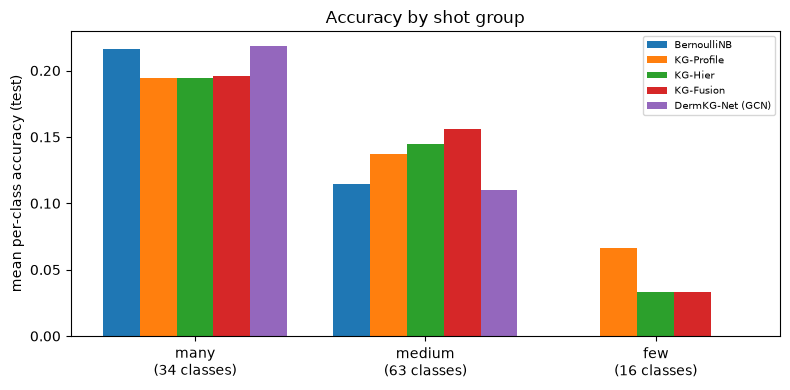

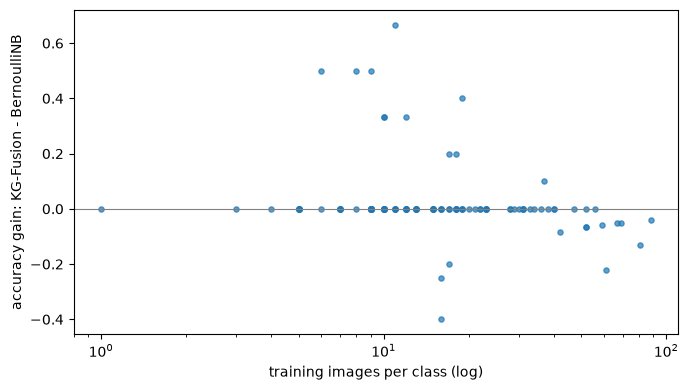

mean gain few / medium / many: [np.float64(0.031), np.float64(0.042), np.float64(-0.02)]


In [15]:
SHOW = [best_base, "KG-Profile", "KG-Hier", "KG-Fusion", "DermKG-Net (GCN)"]
SHOW = [s for s in dict.fromkeys(SHOW) if s in res.index]
fig, ax = plt.subplots(figsize=(8, 4))
w = 0.8 / len(SHOW)
for k, n in enumerate(SHOW):
    ax.bar(np.arange(3) + k * w, res.loc[n, ["many", "medium", "few"]].values, w, label=n)
ax.set_xticks(np.arange(3) + 0.4 - w / 2)
ax.set_xticklabels([f"{g}\n({(shot == g).sum()} classes)" for g in ("many", "medium", "few")])
ax.set_ylabel("mean per-class accuracy (test)"); ax.legend(fontsize=7); ax.set_title("Accuracy by shot group")
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "long_tail.png"), dpi=200); plt.show()

# per-class gain of the best KG model over the best baseline vs. training size
pa, pb = PROBS[best_kg].argmax(1), PROBS[best_base].argmax(1)
acc = lambda p: np.bincount(yte, weights=(p == yte), minlength=K) / np.maximum(np.bincount(yte, minlength=K), 1)
gain = acc(pa) - acc(pb)
fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(n_train, gain, s=14, alpha=0.7); ax.axhline(0, c="gray", lw=0.8); ax.set_xscale("log")
ax.set_xlabel("training images per class (log)"); ax.set_ylabel(f"accuracy gain: {best_kg} - {best_base}")
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "gain_vs_size.png"), dpi=200); plt.show()
print("mean gain few / medium / many:", [round(gain[shot == g].mean(), 3) for g in ("few", "medium", "many")])

## 10. Skin-type breakdown

Concepts were annotated by dermatologists, so this checks whether concept-based diagnosis itself is consistent across Fitzpatrick types (test top-1 accuracy).

In [16]:
st = df.loc[te, "skin_type"].values
fst = pd.DataFrame({n: {t: (PROBS[n].argmax(1)[st == t] == yte[st == t]).mean() for t in sorted(set(st))}
                    for n in SHOW})
fst["n_test"] = pd.Series(Counter(st))
display(fst.round(3))
fst.to_csv(os.path.join(OUT_DIR, "skin_type_breakdown.csv"))

,BernoulliNB,KG-Profile,KG-Hier,KG-Fusion,DermKG-Net (GCN),n_test
FST-1,0.142,0.142,0.142,0.142,0.142,106
FST-2,0.157,0.152,0.162,0.178,0.183,191
FST-3,0.176,0.176,0.168,0.160,0.168,131
FST-4,0.178,0.140,0.131,0.150,0.178,107
FST-5,0.267,0.227,0.227,0.213,0.227,75
FST-6,0.174,0.174,0.174,0.174,0.174,23
FST-unknown,0.286,0.286,0.286,0.286,0.214,14


## 11. Explainability

**Case level.** For KG-Hier, the evidence for disease $d$ over the runner-up $d'$ decomposes over concepts:
$$\Delta_c = x_c\log\frac{p_d(c)}{p_{d'}(c)}+(1-x_c)\log\frac{1-p_d(c)}{1-p_{d'}(c)}$$
combined with the activated clinical rules that support the prediction (the reasoning chain).

KG-Fusion predictions backed by >= 1 activated expert rule: 0.289
  accuracy when rule-backed: 0.251 | not rule-backed: 0.137
true: acne vulgaris | pred: acne vulgaris (0.75) vs runner-up acne (0.25)
present concepts: ['Papule', 'Pustule', 'Erythema', 'Comedo']
concept evidence (pred vs runner-up):
   + Pustule                    +0.56
   + Comedo                     -0.43
   - Plaque                     +0.13
   - Dome-shaped                +0.12
   + Papule                     +0.12
   - Crust                      +0.07
   rule R05 [strong] Comedo -> comedonal disease
   rule R09 [strong] Pustule -> pustular / follicular disease
   rule M002 [strong] Papule + Comedo -> acne vulgaris


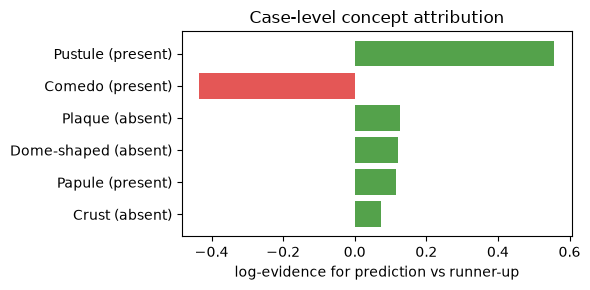

In [17]:
P_exp = PROBS["KG-Fusion"]
pred_f = P_exp.argmax(1)
supported = CS_EXP["te"][np.arange(len(yte)), pred_f] > 0
print(f"KG-Fusion predictions backed by >= 1 activated expert rule: {supported.mean():.3f}")
print(f"  accuracy when rule-backed: {(pred_f[supported] == yte[supported]).mean():.3f} | "
      f"not rule-backed: {(pred_f[~supported] == yte[~supported]).mean():.3f}")


def explain(i, topn=6):
    x = Xte[i]; P = P_exp[i]; d1, d2 = np.argsort(-P)[:2]
    p1, p2 = np.clip(PD_HIER[d1], 1e-4, 1 - 1e-4), np.clip(PD_HIER[d2], 1e-4, 1 - 1e-4)
    delta = x * np.log(p1 / p2) + (1 - x) * np.log((1 - p1) / (1 - p2))
    order = np.argsort(-np.abs(delta))[:topn]
    print(f"true: {DISEASES[yte[i]]} | pred: {DISEASES[d1]} ({P[d1]:.2f}) vs runner-up {DISEASES[d2]} ({P[d2]:.2f})")
    print("present concepts:", [CONCEPTS[j] for j in np.flatnonzero(x)])
    print("concept evidence (pred vs runner-up):")
    for j in order:
        print(f"   {'+' if x[j] else '-'} {CONCEPTS[j]:26s} {delta[j]:+.2f}")
    for k in np.flatnonzero(ACT["te"][i]):
        if T_R[k, d1]:
            print(f"   rule {rules.rule_id[k]} [{rules.strength[k]}] {rules.name[k]}")
    return order, delta


ok_ids = np.flatnonzero((pred_f == yte) & supported)
case = ok_ids[0] if len(ok_ids) else 0
order, delta = explain(case)
fig, ax = plt.subplots(figsize=(6, 3))
ax.barh([CONCEPTS[j] + (" (present)" if Xte[case, j] else " (absent)") for j in order][::-1], delta[order][::-1],
        color=["#54a24b" if v > 0 else "#e45756" for v in delta[order][::-1]])
ax.set_xlabel("log-evidence for prediction vs runner-up"); ax.set_title("Case-level concept attribution")
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "case_attribution.png"), dpi=200); plt.show()

In [18]:
# global: most discriminative concepts per super-category (KG-Hier profile, lift over the global prior)
p_c = Xtr.mean(0)
for s, sname in enumerate(SUPS):
    lift = PD_HIER[d2s == s].mean(0) / p_c
    top = np.argsort(-lift)[:6]
    print(f"{sname:15s}", ", ".join(f"{CONCEPTS[j]} x{lift[j]:.1f}" for j in top))

benign          Salmon x4.9, Cyst x4.5, Warty/Papillomatous x3.6, Exophytic/Fungating x2.7, Pedunculated x2.6, Nodule x2.4
malignant       Blue x9.5, Black x5.3, Translucent x5.0, Telangiectasia x3.7, Pigmented x3.0, Poikiloderma x2.9
non-neoplastic  Abscess x2.3, Macule x1.7, Excoriation x1.4, Sclerosis x1.4, Acuminate x1.4, Induration x1.4


## 12. Error analysis

KG-Fusion errors: 537 / 647
  errors within the true category: 0.536
  errors within the true super-category: 0.624
  errors between diseases with identical KG concept signatures: 0.032
  errors whose exact concept vector occurs in the predicted class in train: 0.709


,true,predicted,count,same_category
0,lupus erythematosus,erythema annulare centrifigum,8,True
1,pityriasis rubra pilaris,psoriasis,6,True
2,scabies,acne vulgaris,5,True
3,sarcoidosis,erythema annulare centrifigum,4,True
4,seborrheic dermatitis,psoriasis,4,True
5,squamous cell carcinoma,neutrophilic dermatoses,4,False
6,folliculitis,acne vulgaris,4,True
7,erythema multiforme,erythema annulare centrifigum,4,True
8,nematode infection,erythema annulare centrifigum,4,True
9,mycosis fungoides,psoriasis,3,False


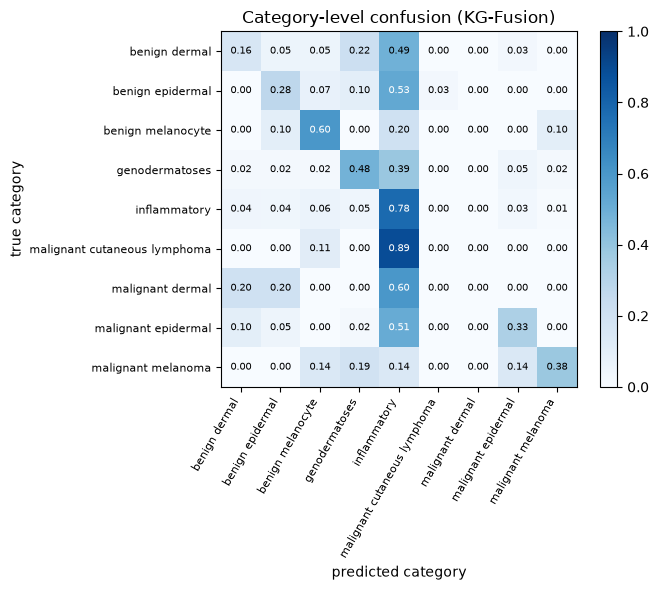

In [19]:
err = pred_f != yte
print(f"KG-Fusion errors: {err.sum()} / {len(yte)}")
print(f"  errors within the true category: {(d2c[pred_f[err]] == d2c[yte[err]]).mean():.3f}")
print(f"  errors within the true super-category: {(d2s[pred_f[err]] == d2s[yte[err]]).mean():.3f}")

# identical binary concept signatures in the KG (see dermkg_build diagnostics)
ch = triples[triples.relation == "CHARACTERIZED_BY"]
sig = ch.groupby("head")["tail"].apply(frozenset).to_dict()
sig = [sig.get(f"Disease:{d}", frozenset()) for d in DISEASES]
same_sig = np.array([sig[a] == sig[b] for a, b in zip(yte[err], pred_f[err])])
print(f"  errors between diseases with identical KG concept signatures: {same_sig.mean():.3f}")
# identical concept vectors: the input itself cannot separate them
dup_input = np.array([any((Xtr[ytr == p] == Xte[np.flatnonzero(err)[k]]).all(1)) for k, p in enumerate(pred_f[err])])
print(f"  errors whose exact concept vector occurs in the predicted class in train: {dup_input.mean():.3f}")

pairs = Counter((DISEASES[a], DISEASES[b]) for a, b in zip(yte[err], pred_f[err]))
conf = pd.DataFrame([(a, b, n, D2CAT[a] == D2CAT[b]) for (a, b), n in pairs.most_common(15)],
                    columns=["true", "predicted", "count", "same_category"])
display(conf)
conf.to_csv(os.path.join(OUT_DIR, "top_confusions.csv"), index=False)

cm = confusion_matrix(d2c[yte], d2c[pred_f], labels=range(len(CATS)), normalize="true")
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(len(CATS))); ax.set_xticklabels(CATS, rotation=60, ha="right", fontsize=8)
ax.set_yticks(range(len(CATS))); ax.set_yticklabels(CATS, fontsize=8)
for i, j in itertools.product(range(len(CATS)), repeat=2):
    ax.text(j, i, f"{cm[i, j]:.2f}", ha="center", va="center", fontsize=7, color="white" if cm[i, j] > 0.5 else "black")
ax.set_xlabel("predicted category"); ax.set_ylabel("true category"); ax.set_title("Category-level confusion (KG-Fusion)")
plt.colorbar(im, fraction=0.046); plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "category_confusion.png"), dpi=200); plt.show()

## 13. Save

In [20]:
summary = {
    "split": {"train": int(tr.sum()), "val": int(va.sum()), "test": int(te.sum())},
    "fusion": {"base": base_name, "alpha": float(A_BEST), "lambda": float(L_BEST)},
    "best_baseline": best_base, "best_kg_model": best_kg,
    "test": {n: {k: (float(v) if isinstance(v, (float, np.floating)) else v) for k, v in TEST[n].items()} for n in res.index},
}
json.dump(summary, open(os.path.join(OUT_DIR, "summary.json"), "w"), indent=1)
np.savez_compressed(os.path.join(OUT_DIR, "test_probs.npz"), y_test=yte, **{n: PROBS[n] for n in res.index})
print("saved:", sorted(os.listdir(OUT_DIR)))

saved: ['figures', 'main_results.csv', 'skin_type_breakdown.csv', 'summary.json', 'test_probs.npz', 'top_confusions.csv', 'val_results.csv']
